# 02 — Segmentasi Citra
Input: `output/01_praproses/<kelas>/` → Output: mask biner di `output/02_mask/<kelas>/`

Alur:
1. **ROI** = kotak tengah (sisi 40% lebar/tinggi citra)
2. **Threshold HSV**: hijau + kuning **aktif**; cokelat + putih **tersedia tapi nonaktif**; Sobel **mati**
3. Morfologi: **open 7** lalu **close 15**
4. **imfill** (isi lubang)
5. Komponen terhubung: buang area < 0,2% citra, **pertahankan yang menyentuh ROI**

> Catatan: cokelat nonaktif berarti bercak cokelat tidak lolos threshold, tapi bercak yang dikelilingi daun biasanya tertutup kembali oleh close + imfill. Cek preview kelas `bercak_daun` untuk memastikan.

In [1]:
from pathlib import Path
import json, random
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from IPython.display import display
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Root proyek = folder pcv_bkpm (otomatis, baik dijalankan dari notebooks/ maupun root)
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "dataset_crop"      # input: citra daun hasil crop, 1 subfolder = 1 kelas
OUT  = ROOT / "output"            # semua hasil notebook disimpan di sini
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
CLASSES = sorted(p.name for p in DATA.iterdir() if p.is_dir())   # label = nama subfolder

def imread(path, flags=cv2.IMREAD_COLOR):          # aman untuk path Windows ber-spasi/non-ASCII
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), flags)

def imwrite(path, img):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    ok, buf = cv2.imencode(path.suffix, img); buf.tofile(str(path)); return ok

def list_images(folder):
    return sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in IMG_EXT)

def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("ROOT   :", ROOT)
print("Kelas  :", CLASSES)

ROOT   : D:\SEMESTER 5\pcv_bkpm
Kelas  : ['bercak_daun', 'sehat', 'ulat', 'virus_gemini']


c:\Users\Shobri\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from scipy.ndimage import binary_fill_holes

IN_PRE   = OUT / "01_praproses"
OUT_MASK = OUT / "02_mask"

# ---------- KONFIGURASI (skala HSV OpenCV: H 0-179, S 0-255, V 0-255) ----------
ROI_FRAC      = 0.40      # sisi kotak ROI tengah = 40% sisi citra
OPEN_K        = 7
CLOSE_K       = 15
MIN_AREA_FRAC = 0.002     # 0,2% dari luas citra
USE_SOBEL     = False     # mati
HSV = {
    "hijau":   dict(aktif=True,  lo=(35, 40, 40),  hi=(85, 255, 255)),
    "kuning":  dict(aktif=True,  lo=(20, 60, 80),  hi=(35, 255, 255)),
    "cokelat": dict(aktif=False, lo=(8, 50, 20),   hi=(20, 255, 200)),
    "putih":   dict(aktif=False, lo=(0, 0, 200),   hi=(179, 40, 255)),
}
display(pd.DataFrame(HSV).T.assign(sobel=USE_SOBEL))
print("Input ada:", IN_PRE.exists(), "| jumlah citra:", sum(len(list_images(IN_PRE / c)) for c in CLASSES))

,aktif,lo,hi,sobel
hijau,True,"(35, 40, 40)","(85, 255, 255)",False
kuning,True,"(20, 60, 80)","(35, 255, 255)",False
cokelat,False,"(8, 50, 20)","(20, 255, 200)",False
putih,False,"(0, 0, 200)","(179, 40, 255)",False


Input ada: True | jumlah citra: 240


## 1. Fungsi-fungsi segmentasi

In [3]:
def hsv_masks(img_bgr):
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    return {n: cv2.inRange(hsv, np.array(c["lo"]), np.array(c["hi"])) for n, c in HSV.items()}

def combine(masks):
    m = np.zeros_like(next(iter(masks.values())))
    for n, c in HSV.items():
        if c["aktif"]:
            m = cv2.bitwise_or(m, masks[n])
    return m

def sobel_edges(img_bgr):     # opsional, default mati (USE_SOBEL = False)
    g = cv2.GaussianBlur(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), (3, 3), 0)
    mag = cv2.magnitude(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    mag = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    return cv2.threshold(mag, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]

def morph(m):
    ko = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (OPEN_K, OPEN_K))
    kc = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (CLOSE_K, CLOSE_K))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, ko)
    return cv2.morphologyEx(m, cv2.MORPH_CLOSE, kc)

def imfill(m):
    return (binary_fill_holes(m > 0) * 255).astype(np.uint8)

def roi_box(shape):
    h, w = shape[:2]
    bh, bw = int(h * ROI_FRAC), int(w * ROI_FRAC)
    y0, x0 = (h - bh) // 2, (w - bw) // 2
    return x0, y0, x0 + bw, y0 + bh

def filter_components(m):
    h, w = m.shape
    n, lab, stats, _ = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=8)
    x0, y0, x1, y1 = roi_box(m.shape)
    touch_roi = set(np.unique(lab[y0:y1, x0:x1])) - {0}
    keep, kept = np.zeros_like(m), 0
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= MIN_AREA_FRAC * h * w and i in touch_roi:
            keep[lab == i] = 255; kept += 1
    return keep, kept

def segment(img_bgr):
    """Return mask akhir + dict tahapan (untuk demo)."""
    st = {}
    st["masks"] = hsv_masks(img_bgr)
    m = combine(st["masks"])
    if USE_SOBEL:
        m = cv2.bitwise_or(m, sobel_edges(img_bgr))
    st["threshold"] = m
    st["morph"] = morph(m)
    st["imfill"] = imfill(st["morph"])
    st["final"], st["n_comp"] = filter_components(st["imfill"])
    return st["final"], st

def overlay(img_bgr, mask, color=(0, 0, 255)):
    out = img_bgr.copy()
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out, cnts, -1, color, 2)
    return out
print("Fungsi siap.")

Fungsi siap.


## 2. Demo tahap demi tahap pada 1 citra

Demo: bercak_daun IMG_20240217_151314.png


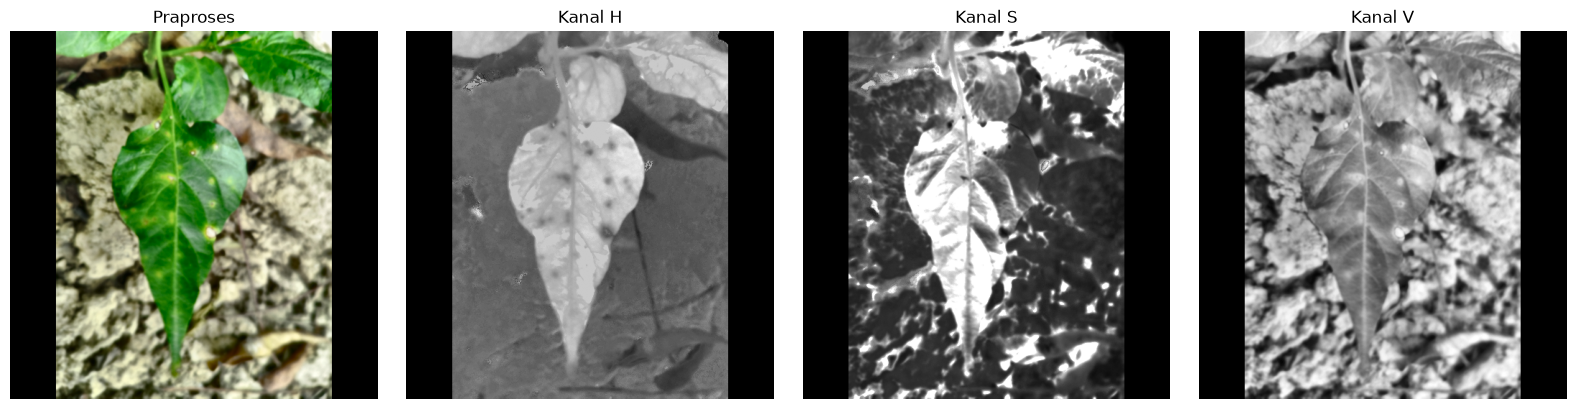

In [4]:
DEMO_CLASS = "bercak_daun" if "bercak_daun" in CLASSES else CLASSES[0]
demo_path = list_images(IN_PRE / DEMO_CLASS)[0]
demo = imread(demo_path)
final, st = segment(demo)
print("Demo:", DEMO_CLASS, demo_path.name)

hsv = cv2.cvtColor(demo, cv2.COLOR_BGR2HSV)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(rgb(demo)); axes[0].set_title("Praproses")
for ax, i, t in zip(axes[1:], range(3), ["Kanal H", "Kanal S", "Kanal V"]):
    ax.imshow(hsv[..., i], cmap="gray"); ax.set_title(t)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

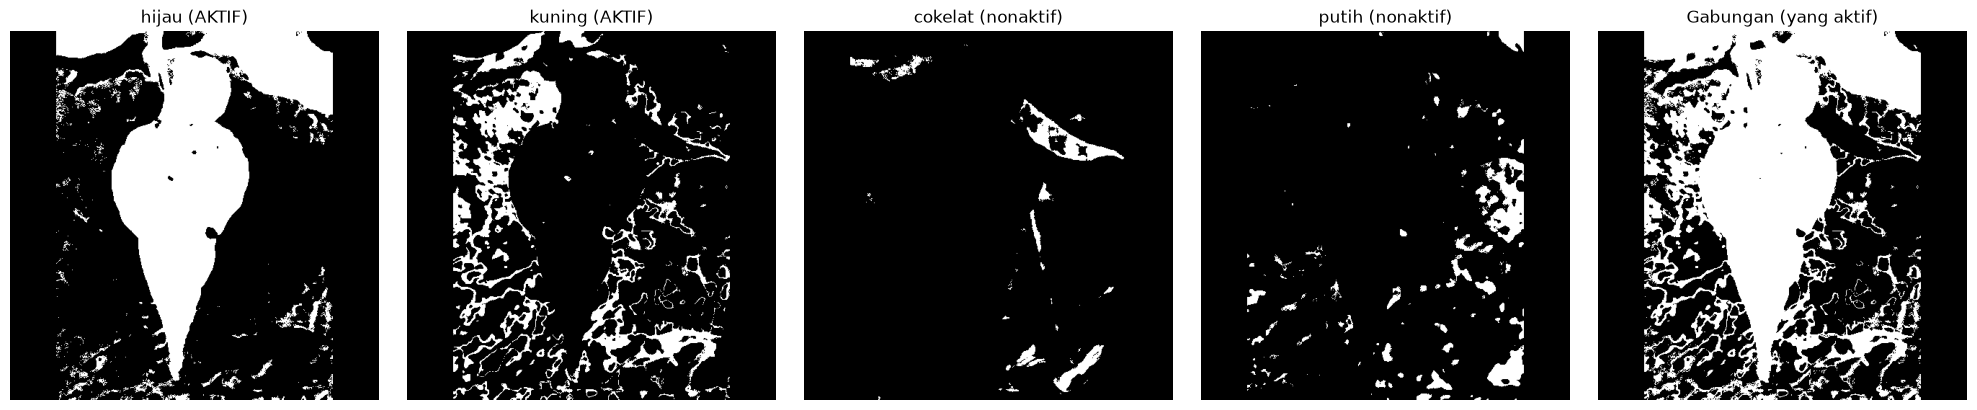

In [5]:
# Threshold per warna (judul menandai aktif / nonaktif)
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (n, m) in zip(axes[:4], st["masks"].items()):
    ax.imshow(m, cmap="gray"); ax.set_title(f"{n} ({'AKTIF' if HSV[n]['aktif'] else 'nonaktif'})")
axes[4].imshow(st["threshold"], cmap="gray"); axes[4].set_title("Gabungan (yang aktif)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

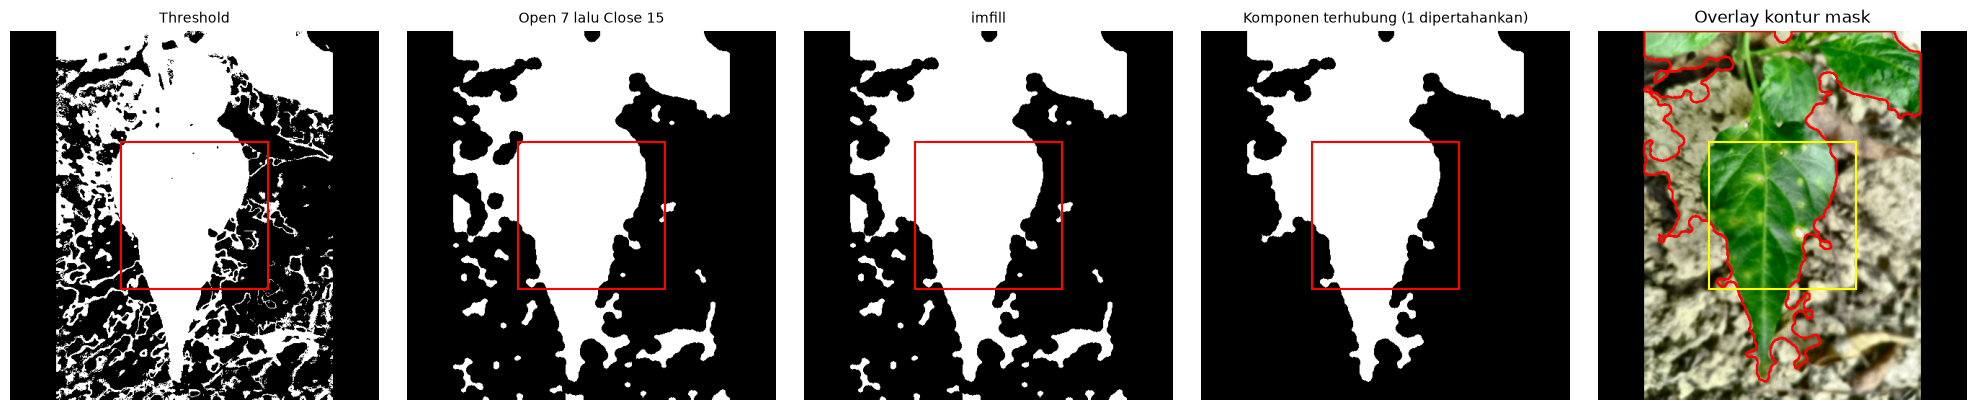

ROI (kotak merah/kuning): x 154-358, y 154-358 | luas mask = 32.9% citra


In [6]:
# Morfologi -> imfill -> komponen terhubung + ROI
x0, y0, x1, y1 = roi_box(demo.shape)
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (k, t) in zip(axes[:4], [("threshold", "Threshold"), ("morph", f"Open {OPEN_K} lalu Close {CLOSE_K}"),
                                  ("imfill", "imfill"), ("final", f"Komponen terhubung ({st['n_comp']} dipertahankan)")]):
    ax.imshow(st[k], cmap="gray"); ax.set_title(t, fontsize=10)
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", lw=1.5))
axes[4].imshow(rgb(overlay(demo, final))); axes[4].set_title("Overlay kontur mask")
axes[4].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="yellow", lw=1.5))
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()
print(f"ROI (kotak merah/kuning): x {x0}-{x1}, y {y0}-{y1} | luas mask = {(final > 0).mean() * 100:.1f}% citra")

## 3. Preview 1 citra per kelas (kiri: citra + kontur, kanan: mask)

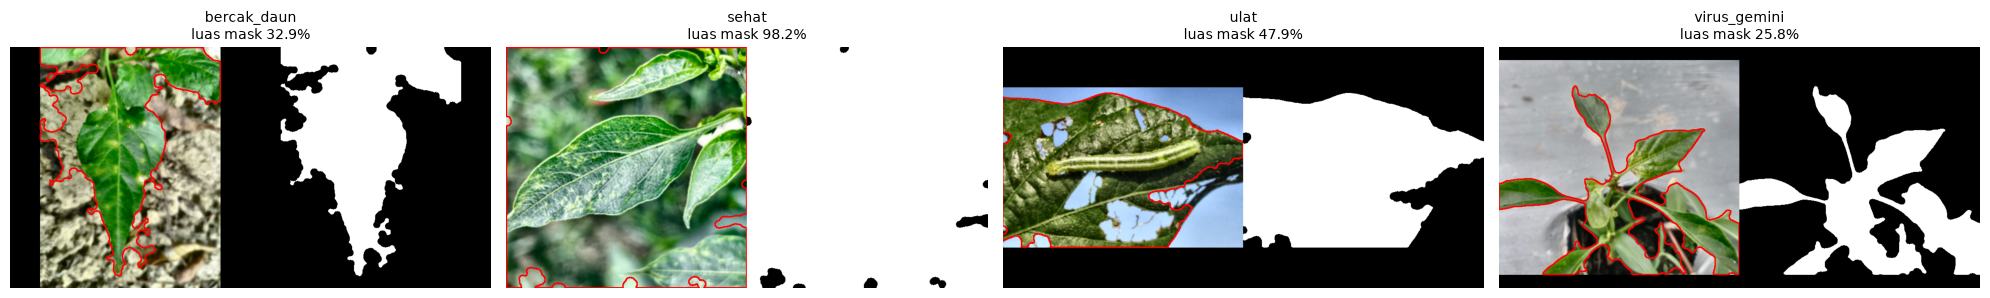

In [7]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(5 * len(CLASSES), 4.5))
axes = np.atleast_1d(axes)
for ax, c in zip(axes, CLASSES):
    p = list_images(IN_PRE / c)[0]; im = imread(p); m, _ = segment(im)
    ax.imshow(rgb(np.hstack([overlay(im, m), cv2.cvtColor(m, cv2.COLOR_GRAY2BGR)])))
    ax.set_title(f"{c}\nluas mask {(m > 0).mean() * 100:.1f}%", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Proses seluruh dataset → `output/02_mask/<kelas>/`

In [8]:
records = []
for c in CLASSES:
    for p in tqdm(list_images(IN_PRE / c), desc=c):
        m, st_ = segment(imread(p))
        imwrite(OUT_MASK / c / (p.stem + ".png"), m)
        records.append({"kelas": c, "file": p.name, "area_ratio": (m > 0).mean(),
                        "n_komponen": st_["n_comp"], "kosong": not m.any()})
df_seg = pd.DataFrame(records)
summary = df_seg.groupby("kelas").agg(jumlah=("file", "count"), area_mean=("area_ratio", "mean"),
                                      area_min=("area_ratio", "min"), area_max=("area_ratio", "max"),
                                      komponen_mean=("n_komponen", "mean"), mask_kosong=("kosong", "sum")).round(3)
display(summary)
print("Total mask kosong:", int(df_seg.kosong.sum()), "| disimpan di:", OUT_MASK)

virus_gemini: 100%|██████████| 90/90 [00:04<00:00, 18.36it/s]


,jumlah,area_mean,area_min,area_max,komponen_mean,mask_kosong
kelas,,,,,,
bercak_daun,50,0.353,0.153,0.635,1.100,0
sehat,50,0.363,0.172,0.994,1.060,0
ulat,50,0.381,0.114,0.749,1.020,0
virus_gemini,90,0.278,0.092,0.517,1.156,0


Total mask kosong: 0 | disimpan di: D:\SEMESTER 5\pcv_bkpm\output\02_mask


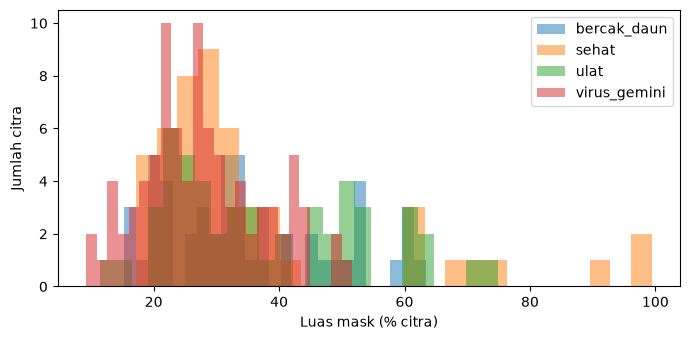

Citra perlu dicek manual (mask <5% atau >85%): 3


,kelas,file,area_ratio,n_komponen,kosong
53,sehat,Healthy Leaf00243.png,0.923386,1,False
50,sehat,Healthy Leaf00151.png,0.982384,1,False
54,sehat,Healthy Leaf00253.png,0.994164,1,False


In [9]:
# Sebaran luas mask per kelas + daftar citra bermasalah (mask hampir kosong / hampir penuh)
fig, ax = plt.subplots(figsize=(7, 3.5))
for c in CLASSES:
    ax.hist(df_seg[df_seg.kelas == c].area_ratio * 100, bins=25, alpha=0.5, label=c)
ax.set_xlabel("Luas mask (% citra)"); ax.set_ylabel("Jumlah citra"); ax.legend(); plt.tight_layout(); plt.show()

suspect = df_seg[(df_seg.area_ratio < 0.05) | (df_seg.area_ratio > 0.85)].sort_values("area_ratio")
print(f"Citra perlu dicek manual (mask <5% atau >85%): {len(suspect)}")
display(suspect.head(15))

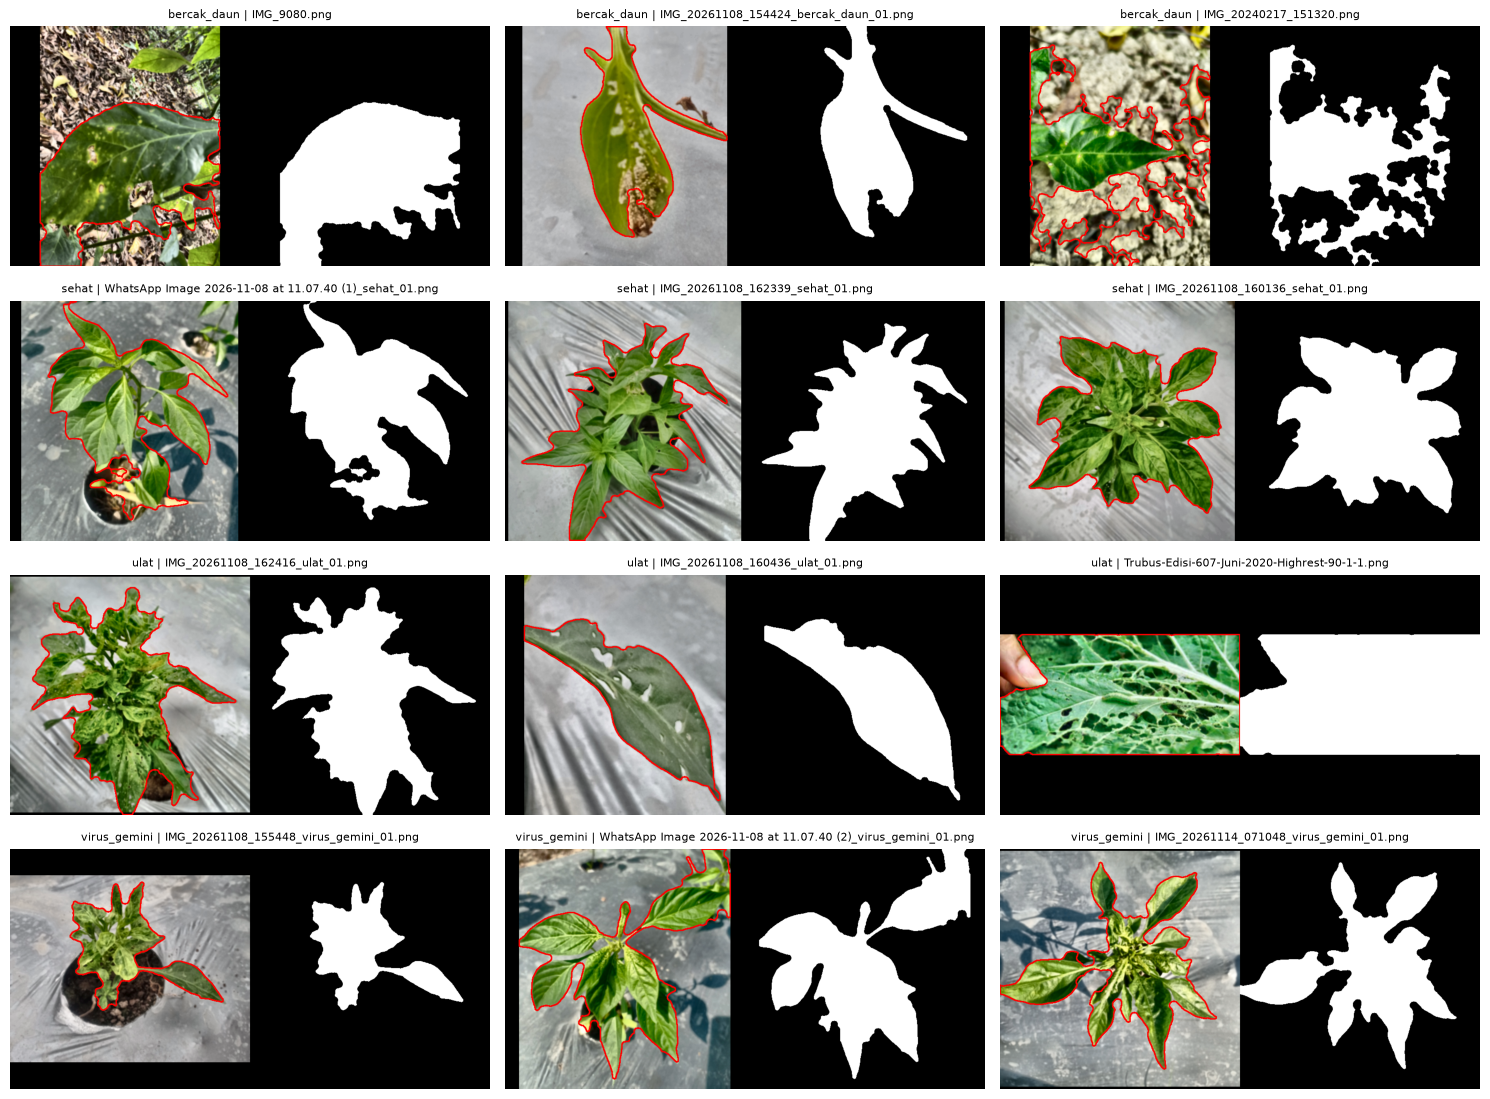

In [10]:
# Preview per kelas: N citra acak (citra + kontur | mask)
N_PREVIEW = 3
rng = random.Random(SEED)
fig, axes = plt.subplots(len(CLASSES), N_PREVIEW, figsize=(5 * N_PREVIEW, 2.8 * len(CLASSES)))
axes = np.atleast_2d(axes)
for i, c in enumerate(CLASSES):
    files = list_images(IN_PRE / c)
    for j, p in enumerate(rng.sample(files, min(N_PREVIEW, len(files)))):
        im = imread(p); m = imread(OUT_MASK / c / (p.stem + ".png"), cv2.IMREAD_GRAYSCALE)
        axes[i, j].imshow(rgb(np.hstack([overlay(im, m), cv2.cvtColor(m, cv2.COLOR_GRAY2BGR)])))
        axes[i, j].set_title(f"{c} | {p.name}", fontsize=8)
    for j in range(N_PREVIEW): axes[i, j].axis("off")
plt.tight_layout(); plt.show()